<a href="https://colab.research.google.com/github/sarans2223/PCA-/blob/main/pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [2]:
X = pd.read_csv("arcene_train.data", sep=" ", header=None)
y = pd.read_csv("arcene_train.labels", header=None)

In [3]:
print("Features:", X.shape)
print("Labels:", y.shape)

Features: (100, 10001)
Labels: (100, 1)


In [4]:
print(X.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Columns: 10001 entries, 0 to 10000
dtypes: float64(1), int64(10000)
memory usage: 7.6 MB
None


In [5]:
X.describe()

,0,1,2,3,4,5,6,7,8,9,...,9991,9992,9993,9994,9995,9996,9997,9998,9999,10000
count,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,0.0
mean,37.060000,35.330000,56.50000,329.860000,17.110000,412.090000,232.330000,6.510000,48.170000,63.690000,...,396.480000,45.920000,18.210000,106.070000,165.350000,197.650000,0.360000,88.530000,365.750000,NaN
std,49.763647,37.690943,68.64011,164.264508,26.348057,108.375152,186.106142,13.149102,57.624009,91.626349,...,233.176462,47.886161,23.914112,141.747054,145.380752,113.122118,2.110675,109.698619,106.055386,NaN
min,0.000000,0.000000,0.00000,27.000000,0.000000,181.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,41.000000,0.000000,0.000000,0.000000,NaN
25%,0.000000,0.000000,0.00000,213.750000,0.000000,314.250000,0.000000,0.000000,0.000000,0.000000,...,309.000000,0.000000,0.000000,0.000000,0.000000,94.500000,0.000000,0.000000,314.500000,NaN
50%,15.000000,25.000000,19.50000,333.500000,0.000000,441.000000,266.000000,0.000000,30.000000,0.500000,...,468.500000,34.500000,2.500000,48.500000,186.000000,167.000000,0.000000,38.500000,364.500000,NaN
75%,57.500000,59.750000,107.25000,443.000000,29.000000,501.250000,422.750000,4.500000,79.250000,125.000000,...,579.250000,75.250000,34.250000,140.000000,276.500000,295.750000,0.000000,165.500000,446.500000,NaN
max,188.000000,218.000000,236.00000,677.000000,99.000000,583.000000,493.000000,55.000000,202.000000,391.000000,...,654.000000,195.000000,83.000000,656.000000,485.000000,422.000000,18.000000,392.000000,533.000000,NaN


In [6]:
print("Missing values:", X.isnull().sum().sum())

Missing values: 100


In [7]:
imputer = SimpleImputer(strategy="median")

X = imputer.fit_transform(X)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [10000]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [12]:
pca = PCA()

X_pca = pca.fit_transform(X_scaled)


In [13]:
explained_variance = pca.explained_variance_ratio_


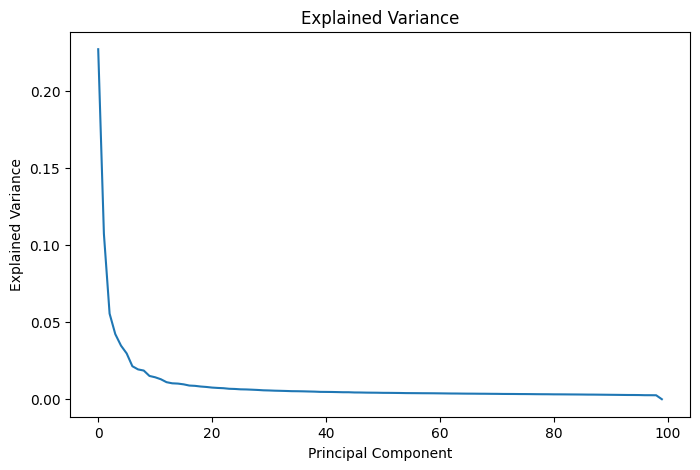

In [14]:
plt.figure(figsize=(8,5))

plt.plot(explained_variance)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance")
plt.title("Explained Variance")

plt.show()

In [16]:
cumulative_variance = np.cumsum(explained_variance)

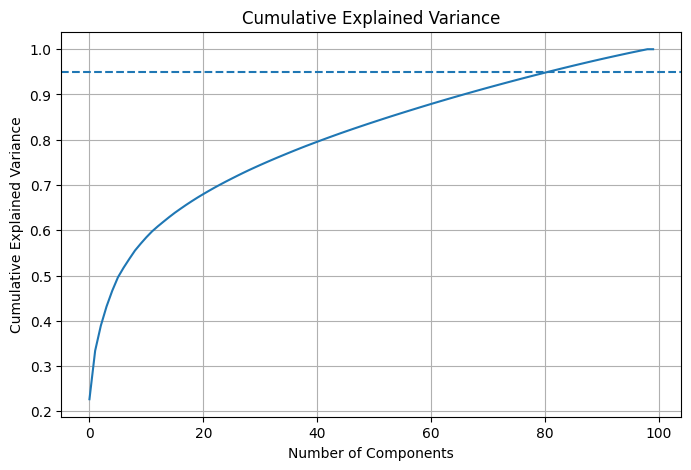

In [17]:
plt.figure(figsize=(8,5))

plt.plot(cumulative_variance)

plt.axhline(0.95, linestyle="--")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.grid()
plt.show()

In [18]:
n_components = np.argmax(cumulative_variance >= 0.95) + 1

print("Number of components:", n_components)


Number of components: 82


In [19]:
pca = PCA(n_components=n_components)

X_reduced = pca.fit_transform(X_scaled)

In [ ]:
print("Original dimensions:", X_scaled.shape)
print("Reduced dimensions:", X_reduced.shape)

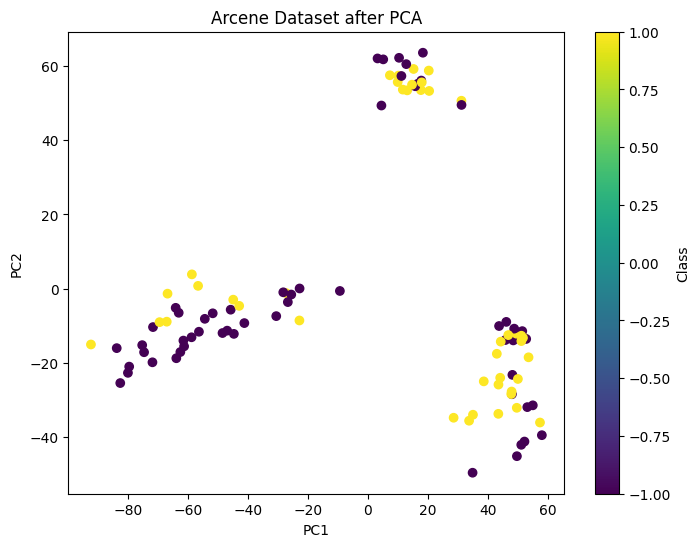

In [20]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=y.values.flatten()
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Arcene Dataset after PCA")

plt.colorbar(label="Class")

plt.show()

In [21]:
print("Original number of features:", X_scaled.shape[1])
print("Reduced number of features:", X_reduced.shape[1])

reduction = (1 - X_reduced.shape[1] / X_scaled.shape[1]) * 100

print("Dimensionality reduction:", round(reduction, 2), "%")

Original number of features: 10000
Reduced number of features: 82
Dimensionality reduction: 99.18 %
